# F-JEPA : prédiction d'arrêts non planifiés sur la Tablette mouleuse

**Données.** Export Teeptrak brut de la **Tablette mouleuse**, du 01/09/2025 au 01/09/2026 (`input/export-137588`) :
- **Logs de performance** : chaque cycle, micro-arrêt et arrêt, horodaté à la seconde. On y trouve 4 231 arrêts non planifiés, qualifiés par zone et par composant.
- **Logs d'événements** : une impulsion capteur par cycle, environ toutes les 29 s.

**Question.** À un instant où la machine tourne, peut-on prédire qu'un **arrêt non planifié va commencer dans les 30 prochaines minutes**, à partir des 4 dernières heures ?

**Démarche**
1. Agréger les logs en une série de **pas de 5 minutes** (cadence, dispersion des cycles, micro-arrêts, écarts entre impulsions capteur, arrêts, heure, jour).
2. Définir la cible et faire un découpage **dans le temps** : train de septembre 2025 à avril 2026, test de mai à août 2026.
3. Établir des baselines : règles simples, régression logistique, gradient boosting sur des features manuelles.
4. **Pré-entraîner un JEPA** sur des fenêtres de 4 h (48 tokens de 5 min), sans étiquettes.
5. Évaluer de trois façons : sonde linéaire, score de surprise, fine-tuning supervisé comparé à un Transformer initialisé au hasard.
6. Analyser par zone, puis conclure.

Les fichiers Excel d'origine sont seulement lus. Un cache (`cache/*.pkl`) évite de les relire à chaque exécution, car la première lecture prend environ 4 minutes. L'exécution complète prend environ 15 à 20 minutes sur CPU.

## 0. Paramètres

In [1]:
import os, re, time, copy, glob
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings("ignore", message="enable_nested_tensor")
pd.set_option("display.width", 160)

EXPORT_DIR = Path(os.environ.get("FJEPA_EXPORT", "../input/export-137588"))
CACHE_DIR = Path("cache"); CACHE_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results_mouleuse"); RESULTS_DIR.mkdir(exist_ok=True)

BIN = "5min"            # pas de temps d'un token
WINDOW = 48             # 48 x 5 min = 4 h d'historique
HORIZON = 6             # cible : arrêt non planifié dans les 6 prochains pas (30 min)
TRAIN_END = "2026-04-30 23:59"   # train : sept. 2025 -> avril 2026 (8 mois)
TEST_START = "2026-05-01"        # test  : mai -> août 2026 (4 mois)
MIN_STOP_S = 0          # durée minimale d'un arrêt pour compter comme cible (0 = tous)

## 1. Chargement

On renomme les colonnes et on retire les espaces parasites dans `Issue type lv2`. On écarte aussi 2 lignes tronquées en bord d'export, repérables à leur Id entre parenthèses.

In [2]:
def load_export():
    """Charge les deux types d'exports Teeptrak (avec cache pickle, la lecture Excel prend ~4 min)."""
    pc, ec = CACHE_DIR / "perf.pkl", CACHE_DIR / "events.pkl"
    if pc.exists() and ec.exists():
        return pd.read_pickle(pc), pd.read_pickle(ec)
    perf = pd.concat([pd.read_excel(f, header=1) for f in sorted(EXPORT_DIR.glob("export-*-[0-9]*.xlsx")) if "events" not in f.name])
    ev = pd.concat([pd.read_excel(f) for f in sorted(EXPORT_DIR.glob("export-*-events-*.xlsx"))])
    perf.to_pickle(pc); ev.to_pickle(ec)
    return perf, ev

t0 = time.time()
perf, ev = load_export()
perf.columns = [" ".join(c.replace("\xa0", " ").split()).replace(" ?", "?") for c in perf.columns]
perf = perf.rename(columns={"Commencé à": "debut", "Terminé à": "fin", "Est-ce une perte?": "perte",
                            "Issue type lv2": "lv2", "Niveau 0": "niveau0", "Type de perte": "zone", "Durée": "duree"})
perf["lv2"] = perf["lv2"].fillna("").str.strip()
perf = perf[~perf["Id"].astype(str).str.startswith("(")]          # 2 lignes tronquées en bord d'export
perf = perf.sort_values("debut").reset_index(drop=True)
ev = ev.sort_values("Event At").reset_index(drop=True)
print(f"{len(perf):,} lignes de performance, {len(ev):,} impulsions cycle ({time.time()-t0:.0f} s)")
print(f"période {perf.debut.min():%d/%m/%Y} -> {perf.fin.max():%d/%m/%Y}, machine(s) : {perf.Machine.unique()}")
perf.groupby("niveau0", dropna=False)["duree"].agg(nb="count", heures=lambda s: round(s.sum() / 3600, 1))

780,215 lignes de performance, 460,486 impulsions cycle (1 s)
période 01/09/2025 -> 01/09/2026, machine(s) : ['Tablette mouleuse']


,nb,heures
niveau0,,
Arrêts non planifiés,4231,278.7
Fermeture,802,2756.4
Performance,382675,455.6
Qualité,4,0.1
NaN,392503,3417.3


### Les arrêts non planifiés

Ce sont nos étiquettes de panne : chaque arrêt est qualifié par une zone (`Type de perte`) et un composant (`Issue type lv2`).

In [3]:
stops = perf[perf.niveau0 == "Arrêts non planifiés"].copy()
print(f"{len(stops)} arrêts non planifiés ; durée médiane {stops.duree.median():.0f} s, "
      f"{(stops.duree >= 300).sum()} >= 5 min, {(stops.duree >= 900).sum()} >= 15 min, {stops.Commentaires.notna().sum()} commentés")
top = (stops.groupby(["zone", "lv2"]).duree.agg(nb="count", heures=lambda s: s.sum() / 3600)
       .sort_values("heures", ascending=False).round(1).head(15))
top

4231 arrêts non planifiés ; durée médiane 107 s, 606 >= 5 min, 130 >= 15 min, 861 commentés


nb  heures
zone               lv2                                      
Zone mouleuse      Mouleuse ALPMA                638    41.9
Zone pré égouttage Pré égouttage saturé          787    37.9
                   Autre                         402    36.6
Zone mouleuse      Mouleuse TECNAL                54    14.8
                   Zone transition plateaux      334    13.7
Zone bassines      Tranchage                     124    12.5
Zone matériel vide Dégerbeuse                    284    11.8
Zone bassines      Transferts                     79    11.3
                   Cliquet                        58     9.4
                   Pont mobile                    37     8.6
Zone pré égouttage Gerbeuse avant pré-égouttage  216     8.5
Arrêt              Non renseigné                 166     8.5
Maturation         Panne                          85     7.4
Zone matériel vide Transfert pieds               154     5.7
Zone mouleuse      Attente plateaux               98     5.3

## 2. Série temporelle par pas de 5 minutes

Pour chaque pas de 5 minutes, on calcule :
- **la cadence** : nombre de cycles normaux, durée moyenne, maximale et écart-type des cycles, temps de cycle cible du produit (27 s ou 18 s) ;
- **la dégradation** : nombre et durée des micro-arrêts (« sous-cadence »), nombre de « sur-cadences » ;
- **le capteur** : nombre d'impulsions, écart moyen et maximal entre deux impulsions ;
- **l'état** : secondes en arrêt non planifié et en fermeture, en production ou non ;
- **le calendrier** : heure et jour de la semaine (sin/cos).

In [4]:
def spread_seconds(df, idx):
    """Secondes passées dans des intervalles [debut, fin) pour chaque pas de temps (gère les intervalles à cheval)."""
    out = np.zeros(len(idx))
    step = pd.Timedelta(BIN)
    t0 = idx[0]
    for s, e in zip(df.debut.values, df.fin.values):
        if e <= s:
            continue
        i0 = int((s - t0) // step); i1 = int((e - t0) // step)
        for i in range(max(i0, 0), min(i1, len(idx) - 1) + 1):
            a = max(s, idx[i]); b = min(e, idx[i] + step)
            out[i] += max((b - a) / np.timedelta64(1, "s"), 0)
    return out

idx = pd.date_range(perf.debut.min().floor(BIN), perf.fin.max().ceil(BIN), freq=BIN)
b = pd.DataFrame(index=idx)
perf["t"] = perf.debut.dt.floor(BIN)
stops["t"] = stops.debut.dt.floor(BIN)
cyc = perf[~perf.perte]
micro = perf[perf.lv2 == "Sous-cadence"]
sur = perf[perf.lv2 == "Sur-cadence"]
b["n_cycles"] = cyc.groupby("t").size()
b["cycle_moy"] = cyc.groupby("t").duree.mean()
b["cycle_max"] = cyc.groupby("t").duree.max()
b["cycle_std"] = cyc.groupby("t").duree.std()
b["n_micro"] = micro.groupby("t").size()
b["micro_s"] = micro.groupby("t").duree.sum()
b["n_sur"] = sur.groupby("t").size()
b["temps_cycle_cible"] = perf.groupby("t")["Temps de cycle"].median()       # 27 s ou 18 s selon le produit
ev["t"] = ev["Event At"].dt.floor(BIN)
gap = ev["Event At"].diff().dt.total_seconds()
ev["gap"] = gap.where(gap < 600)                                           # écart entre impulsions capteur
b["n_impulsions"] = ev.groupby("t").size()
b["impulsion_ecart_moy"] = ev.groupby("t").gap.mean()
b["impulsion_ecart_max"] = ev.groupby("t").gap.max()
b["arret_s"] = spread_seconds(stops, idx)
b["ferme_s"] = spread_seconds(perf[perf.niveau0 == "Fermeture"], idx)
b["arret_debut"] = stops[stops.duree >= MIN_STOP_S].groupby("t").size()
b = b.fillna({c: 0 for c in b.columns if c.startswith(("n_", "micro", "arret", "ferme"))})
b["temps_cycle_cible"] = b["temps_cycle_cible"].ffill().fillna(27)
for c in ["cycle_moy", "cycle_max", "cycle_std", "impulsion_ecart_moy", "impulsion_ecart_max"]:
    b[c] = b[c].fillna(0)
b["en_production"] = (b.n_cycles > 0).astype(float)
hod = b.index.hour + b.index.minute / 60
b["heure_sin"], b["heure_cos"] = np.sin(2 * np.pi * hod / 24), np.cos(2 * np.pi * hod / 24)
b["jour_sin"], b["jour_cos"] = np.sin(2 * np.pi * b.index.dayofweek / 7), np.cos(2 * np.pi * b.index.dayofweek / 7)
print(f"{len(b):,} pas de 5 min, dont {int(b.en_production.sum()):,} avec production")
b.describe().T[["mean", "std", "max"]].round(2)

105,219 pas de 5 min, dont 51,189 avec production


,mean,std,max
n_cycles,3.73,4.19,12.00
cycle_moy,16.49,21.99,972.00
cycle_max,23.48,35.62,1350.00
cycle_std,4.32,12.47,935.50
n_micro,3.20,3.94,12.00
micro_s,17.70,28.47,217.00
n_sur,0.44,1.24,12.00
temps_cycle_cible,26.80,1.23,27.00
n_impulsions,4.38,4.77,13.00
impulsion_ecart_moy,17.15,24.89,599.00


## 3. Cible et découpage

- **Cible** : au moins un arrêt non planifié commence dans les 30 minutes qui suivent la fin de la fenêtre.
- **Instants évalués** : seulement ceux où la machine tourne (au moins 3 cycles dans le pas courant, pas d'arrêt ni de fermeture en cours). Prédire un arrêt quand la machine est déjà arrêtée n'aurait pas de sens.
- **Découpage dans le temps** : train jusqu'au 30/04/2026, test à partir du 01/05/2026. La standardisation est calculée sur le train.

Il y a beaucoup de positifs (25 à 35 %), car la machine s'arrête en moyenne toutes les 26 minutes de production. Pour lire les résultats, deux repères :
- **ROC-AUC** : 0,5 correspond au hasard.
- **Précision top 10 %** : parmi les 10 % d'instants jugés les plus risqués, la part réellement suivie d'un arrêt. C'est ce qui compte pour une alerte.

In [5]:
# Cible : au moins un arrêt non planifié commence dans les HORIZON prochains pas.
fut = b.arret_debut[::-1].rolling(HORIZON, min_periods=1).sum()[::-1].shift(-1).fillna(0)
b["cible"] = (fut > 0).astype(float)
# On ne prédit qu'à des instants où la machine tourne (cycles dans le pas courant, pas d'arrêt en cours).
b["predictible"] = (b.n_cycles >= 3) & (b.arret_s < 60) & (b.ferme_s < 60)
FEATS = [c for c in b.columns if c not in ("cible", "predictible", "arret_debut")]
X_all = b[FEATS].astype(np.float32)
X_all[["micro_s", "arret_s", "ferme_s", "cycle_max", "impulsion_ecart_max"]] = np.log1p(X_all[["micro_s", "arret_s", "ferme_s", "cycle_max", "impulsion_ecart_max"]])
train_rows = X_all.index <= pd.Timestamp(TRAIN_END)
mu, sd = X_all[train_rows].mean(), X_all[train_rows].std().replace(0, 1)
Xn = ((X_all - mu) / sd).values.astype(np.float32)

ends = np.arange(WINDOW - 1, len(b) - HORIZON)          # indice du dernier pas de chaque fenêtre
t_end = b.index[ends]
pred_ok = b.predictible.values[ends]
y_all = b.cible.values[ends]
tr = t_end <= pd.Timestamp(TRAIN_END) - pd.Timedelta(minutes=5 * HORIZON)   # pas de cible qui déborde sur le test
te = t_end >= pd.Timestamp(TEST_START)
trl, tel = tr & pred_ok, te & pred_ok
print(f"{len(FEATS)} variables par pas ; instants prédictibles train {trl.sum():,} / test {tel.sum():,}")
print(f"taux de positifs : train {y_all[trl].mean():.1%}, test {y_all[tel].mean():.1%}")

18 variables par pas ; instants prédictibles train 32,588 / test 12,639
taux de positifs : train 25.5%, test 35.8%


## 4. Baselines

In [6]:
rows = []
def score(name, p, sel=None):
    yy = y_all[tel]
    k = max(1, int(0.1 * len(p)))
    top = np.argsort(-p)[:k]
    rows.append({"modele": name, "roc_auc": roc_auc_score(yy, p), "pr_auc": average_precision_score(yy, p),
                 "precision_top10%": yy[top].mean()})
    return rows[-1]

def window_feats(ends_idx):
    """Features manuelles : dernier pas, moyennes 30 min / 2 h / 4 h, temps depuis le dernier arrêt."""
    last = Xn[ends_idx]
    def mean_last(k):
        cs = np.cumsum(np.vstack([np.zeros((1, Xn.shape[1]), np.float32), Xn]), axis=0)
        return (cs[ends_idx + 1] - cs[ends_idx + 1 - k]) / k
    stop_cum = np.concatenate([[0], np.cumsum(b.arret_debut.values)])
    n_stop_4h = stop_cum[ends_idx + 1] - stop_cum[ends_idx + 1 - WINDOW]
    last_stop = pd.Series(np.where(b.arret_debut.values > 0, np.arange(len(b)), np.nan)).ffill().values
    since = np.nan_to_num(ends_idx - last_stop[ends_idx], nan=10_000)
    return np.column_stack([last, mean_last(6), mean_last(24), mean_last(WINDOW), n_stop_4h, np.log1p(since)])

def logreg(C=0.1):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))

In [7]:
H = window_feats(ends)
since_last = -H[:, -1]
score("temps depuis le dernier arrêt (règle simple)", since_last[tel])
score("nb d'arrêts dans les 4 h précédentes", H[tel, -2])
p_lr = logreg().fit(H[trl], y_all[trl]).predict_proba(H[tel])[:, 1]
score("régression logistique (features manuelles)", p_lr)
gb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0).fit(H[trl], y_all[trl])
p_gb = gb.predict_proba(H[tel])[:, 1]
score("gradient boosting (features manuelles)", p_gb)
pd.DataFrame(rows).round(3)

,modele,roc_auc,pr_auc,precision_top10%
0,temps depuis le dernier arrêt (règle simple),0.560,0.408,0.465
1,nb d'arrêts dans les 4 h précédentes,0.564,0.418,0.511
2,régression logistique (features manuelles),0.575,0.426,0.469
3,gradient boosting (features manuelles),0.563,0.423,0.461


## 5. JEPA

Chaque **pas de 5 minutes est un token**, et une fenêtre de 4 h en contient 48. L'entraînement se déroule ainsi :
- On masque 2 blocs de 20 minutes à 1 heure. Une fois sur deux, un des blocs est placé en fin de fenêtre, pour que le modèle apprenne aussi à « prévoir ».
- L'encodeur de contexte ne voit que les pas visibles.
- Le prédicteur doit retrouver **les embeddings** des pas masqués, produits par l'encodeur cible. Ce dernier est une moyenne mobile exponentielle (EMA) de l'encodeur de contexte.

La perte se calcule dans l'espace latent, pas sur les valeurs brutes. **Aucune étiquette d'arrêt n'est utilisée** pendant cette phase.

In [8]:
D_MODEL, N_LAYERS, N_HEADS, PRED_LAYERS = 64, 2, 4, 1
EPOCHS, BATCH_SIZE, LR = 15, 256, 1e-3
EMA_MOMENTUM = (0.99, 0.999)
MASK_BLOCKS, MASK_BLOCK_LEN = 2, (4, 12)      # 2 blocs de 20 min à 1 h masqués
PRETRAIN_STRIDE = 6                           # une fenêtre toutes les 30 min pour le pré-entraînement
SEEDS = [0, 1]
torch.set_num_threads(max(1, os.cpu_count() or 1))

def get_windows(end_idx):
    off = np.arange(-WINDOW + 1, 1)
    return torch.from_numpy(Xn[end_idx[:, None] + off])

In [9]:
class Encoder(nn.Module):
    def __init__(self, n_feat, d=D_MODEL, layers=N_LAYERS, heads=N_HEADS):
        super().__init__()
        self.inp = nn.Linear(n_feat, d)
        self.pos = nn.Parameter(torch.randn(1, WINDOW, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers)
        self.norm = nn.LayerNorm(d)

    def forward(self, x, hide=None):
        """hide : (B, W) bool, True = pas masqué (invisible pour l'attention)."""
        return self.norm(self.tf(self.inp(x) + self.pos, src_key_padding_mask=hide))


class Predictor(nn.Module):
    def __init__(self, d=D_MODEL, layers=PRED_LAYERS, heads=N_HEADS):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, WINDOW, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers)
        self.out = nn.Linear(d, d)

    def forward(self, ctx, hide):
        h = torch.where(hide[..., None], self.mask_token.expand_as(ctx), ctx) + self.pos
        return self.out(self.tf(h))


def sample_mask(batch, gen):
    """Blocs contigus masqués ; une fois sur deux, un bloc colle à la fin (le modèle apprend à « prévoir »)."""
    m = np.zeros((batch, WINDOW), dtype=bool)
    for i in range(batch):
        for k in range(MASK_BLOCKS):
            L = gen.integers(MASK_BLOCK_LEN[0], MASK_BLOCK_LEN[1] + 1)
            start = WINDOW - L if (k == 0 and gen.random() < 0.5) else gen.integers(0, WINDOW - L + 1)
            m[i, start:start + L] = True
    return torch.from_numpy(m)


class JEPA(nn.Module):
    def __init__(self, n_feat):
        super().__init__()
        self.context = Encoder(n_feat)
        self.target = copy.deepcopy(self.context)
        for p in self.target.parameters():
            p.requires_grad_(False)
        self.predictor = Predictor()

    def loss(self, x, hide):
        with torch.no_grad():
            tgt = F.layer_norm(self.target(x), (D_MODEL,))
        pred = self.predictor(self.context(x, hide), hide)
        return F.smooth_l1_loss(pred[hide], tgt[hide])

    @torch.no_grad()
    def ema_update(self, m):
        for pc, pt in zip(self.context.parameters(), self.target.parameters()):
            pt.mul_(m).add_(pc.detach(), alpha=1 - m)

    @torch.no_grad()
    def embed(self, x):
        h = self.target(x)
        return torch.cat([h[:, -1], h[:, -6:].mean(1), h.mean(1)], dim=1)   # dernier pas, 30 min, 4 h

    @torch.no_grad()
    def surprise(self, x):
        """Erreur de prédiction des 30 dernières minutes à partir des 3 h 30 précédentes (score non supervisé)."""
        hide = torch.zeros(x.shape[:2], dtype=torch.bool); hide[:, -6:] = True
        tgt = F.layer_norm(self.target(x), (D_MODEL,))
        pred = self.predictor(self.context(x, hide), hide)
        return (pred[:, -6:] - tgt[:, -6:]).pow(2).mean((1, 2))

### Pré-entraînement (sur la période train uniquement)

11,602 fenêtres de pré-entraînement
  seed 0 epoch   5  perte 0.0977
  seed 0 epoch  10  perte 0.0960
  seed 0 epoch  15  perte 0.0977
  seed 1 epoch   5  perte 0.0876
  seed 1 epoch  10  perte 0.0811
  seed 1 epoch  15  perte 0.0837
pré-entraînement : 606 s


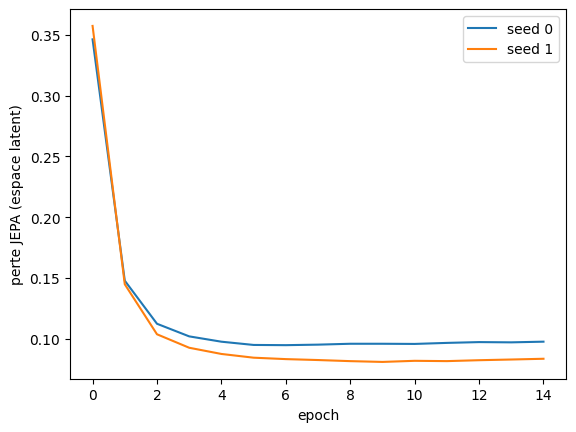

In [10]:
def pretrain(end_idx, seed):
    torch.manual_seed(seed); gen = np.random.default_rng(seed)
    model = JEPA(Xn.shape[1])
    params = list(model.context.parameters()) + list(model.predictor.parameters())
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.05)
    steps = EPOCHS * int(np.ceil(len(end_idx) / BATCH_SIZE))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=steps, pct_start=0.1)
    step, hist = 0, []
    for ep in range(EPOCHS):
        model.train(); tot = 0.0
        perm = gen.permutation(len(end_idx))
        for i in range(0, len(end_idx), BATCH_SIZE):
            x = get_windows(end_idx[perm[i:i + BATCH_SIZE]])
            loss = model.loss(x, sample_mask(len(x), gen))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
            model.ema_update(EMA_MOMENTUM[0] + (EMA_MOMENTUM[1] - EMA_MOMENTUM[0]) * step / steps); step += 1
            tot += loss.item() * len(x)
        hist.append(tot / len(end_idx))
        if (ep + 1) % 5 == 0:
            print(f"  seed {seed} epoch {ep + 1:3d}  perte {hist[-1]:.4f}")
    model.eval()
    return model, hist

# Pré-entraînement sur toutes les fenêtres du train (production ou non), sans étiquettes.
pre_idx = ends[tr][::PRETRAIN_STRIDE]
print(f"{len(pre_idx):,} fenêtres de pré-entraînement")
models, histories = {}, {}
t0 = time.time()
for s in SEEDS:
    models[s], histories[s] = pretrain(pre_idx, s)
    torch.save(models[s].state_dict(), RESULTS_DIR / f"jepa_mouleuse_seed{s}.pt")
print(f"pré-entraînement : {time.time() - t0:.0f} s")
for s, h in histories.items():
    plt.plot(h, label=f"seed {s}")
plt.xlabel("epoch"); plt.ylabel("perte JEPA (espace latent)"); plt.legend(); plt.show()

## 6. Évaluation

On évalue le JEPA de trois façons :
- **Sonde linéaire** : on gèle l'encodeur et on entraîne une régression logistique sur ses embeddings. C'est la mesure standard de la qualité des représentations.
- **Score de surprise** : l'erreur du prédicteur sur les 30 dernières minutes, sans aucune étiquette.
- **Embeddings ajoutés aux features manuelles** dans le gradient boosting.

In [11]:
@torch.no_grad()
def batched(fn, end_idx, bs=2048):
    return torch.cat([fn(get_windows(end_idx[i:i + bs])) for i in range(0, len(end_idx), bs)]).numpy()

probe_preds = []
for s, model in models.items():
    Ztr, Zte = batched(model.embed, ends[trl]), batched(model.embed, ends[tel])
    print(f"seed {s}: écart-type moyen des embeddings {Zte.std(0).mean():.3f} (≈ 0 = effondrement)")
    p = logreg().fit(Ztr, y_all[trl]).predict_proba(Zte)[:, 1]
    probe_preds.append(p)
    score(f"JEPA + sonde linéaire (seed {s})", p)
    score(f"JEPA score de surprise, non supervisé (seed {s})", batched(model.surprise, ends[tel]))
    # JEPA + features manuelles, dans le même boosting
    gbz = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0)
    gbz.fit(np.hstack([H[trl], Ztr]), y_all[trl])
    score(f"boosting features manuelles + embeddings JEPA (seed {s})", gbz.predict_proba(np.hstack([H[tel], Zte]))[:, 1])
p_probe = np.mean(probe_preds, axis=0)
pd.DataFrame(rows).round(3)

seed 0: écart-type moyen des embeddings 0.775 (≈ 0 = effondrement)
seed 1: écart-type moyen des embeddings 0.705 (≈ 0 = effondrement)


,modele,roc_auc,pr_auc,precision_top10%
0,temps depuis le dernier arrêt (règle simple),0.560,0.408,0.465
1,nb d'arrêts dans les 4 h précédentes,0.564,0.418,0.511
2,régression logistique (features manuelles),0.575,0.426,0.469
3,gradient boosting (features manuelles),0.563,0.423,0.461
4,JEPA + sonde linéaire (seed 0),0.557,0.413,0.466
5,"JEPA score de surprise, non supervisé (seed 0)",0.516,0.364,0.348
6,boosting features manuelles + embeddings JEPA ...,0.552,0.397,0.424
7,JEPA + sonde linéaire (seed 1),0.565,0.421,0.492
8,"JEPA score de surprise, non supervisé (seed 1)",0.501,0.356,0.328
9,boosting features manuelles + embeddings JEPA ...,0.560,0.411,0.442


### Fine-tuning : le pré-entraînement JEPA aide-t-il ?

On entraîne le même Transformer de façon supervisée, avec deux initialisations : **(a)** l'encodeur JEPA, **(b)** une initialisation aléatoire. Si (a) bat (b), le pré-entraînement apporte quelque chose.

In [12]:
FT_EPOCHS = 2
FT_STRIDE = 2      # on garde un instant sur deux pour accélérer le fine-tuning sur CPU
class Classifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.enc = encoder
        self.head = nn.Sequential(nn.Linear(3 * D_MODEL, 64), nn.GELU(), nn.Linear(64, 1))
    def forward(self, x):
        h = self.enc(x)
        return self.head(torch.cat([h[:, -1], h[:, -6:].mean(1), h.mean(1)], 1)).squeeze(-1)

def finetune(encoder, seed):
    torch.manual_seed(seed); gen = np.random.default_rng(seed)
    clf = Classifier(encoder)
    opt = torch.optim.AdamW([{"params": clf.enc.parameters(), "lr": 2e-4}, {"params": clf.head.parameters(), "lr": 1e-3}], weight_decay=0.05)
    idx_tr, ytr = ends[trl][::FT_STRIDE], torch.from_numpy(y_all[trl][::FT_STRIDE].astype(np.float32))
    pos_w = (1 - ytr.mean()) / ytr.mean()
    for ep in range(FT_EPOCHS):
        clf.train(); perm = gen.permutation(len(idx_tr))
        for i in range(0, len(idx_tr), BATCH_SIZE):
            j = perm[i:i + BATCH_SIZE]
            loss = F.binary_cross_entropy_with_logits(clf(get_windows(idx_tr[j])), ytr[j], pos_weight=pos_w)
            opt.zero_grad(); loss.backward(); opt.step()
    clf.eval()
    return batched(lambda x: torch.sigmoid(clf(x)), ends[tel])

t0 = time.time()
for s in SEEDS:
    score(f"Transformer supervisé, initialisé par le JEPA (seed {s})", finetune(copy.deepcopy(models[s].target), s))
    score(f"Transformer supervisé, initialisation aléatoire (seed {s})", finetune(Encoder(Xn.shape[1]), s))
print(f"fine-tuning : {time.time() - t0:.0f} s")

fine-tuning : 114 s


### Synthèse (période de test)

In [13]:
res = pd.DataFrame(rows)
res.to_csv(RESULTS_DIR / "metrics_mouleuse.csv", index=False)
res["famille"] = res.modele.str.replace(r" \(seed \d\)", "", regex=True)
summary = res.groupby("famille", sort=False).agg(roc_auc=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"),
                                                  pr_auc=("pr_auc", "mean"), precision_top10=("precision_top10%", "mean")).round(3).fillna("")
print(f"Test mai -> août 2026 : {tel.sum():,} instants, {y_all[tel].mean():.1%} suivis d'un arrêt dans les 30 min "
      f"(hasard : ROC-AUC 0,5 ; PR-AUC et précision ≈ {y_all[tel].mean():.3f})")
summary

Test mai -> août 2026 : 12,639 instants, 35.8% suivis d'un arrêt dans les 30 min (hasard : ROC-AUC 0,5 ; PR-AUC et précision ≈ 0.358)


,roc_auc,roc_auc_std,pr_auc,precision_top10
famille,,,,
temps depuis le dernier arrêt (règle simple),0.560,,0.408,0.465
nb d'arrêts dans les 4 h précédentes,0.564,,0.418,0.511
régression logistique (features manuelles),0.575,,0.426,0.469
gradient boosting (features manuelles),0.563,,0.423,0.461
JEPA + sonde linéaire,0.561,0.005,0.417,0.479
"JEPA score de surprise, non supervisé",0.508,0.011,0.360,0.338
boosting features manuelles + embeddings JEPA,0.556,0.005,0.404,0.433
"Transformer supervisé, initialisé par le JEPA",0.563,0.001,0.420,0.457
"Transformer supervisé, initialisation aléatoire",0.577,0.003,0.432,0.497


### Par zone de panne

In [14]:
# Quelles zones sont les mieux anticipées ? On compare, pour chaque zone, les instants suivis d'un arrêt de cette zone
# à tous les instants négatifs (score du meilleur modèle JEPA et du boosting).
st = stops[["t", "zone"]].copy()
st["pos"] = b.index.get_indexer(st.t)
zone_of = {}
for z, g in st.groupby("zone"):
    m = np.zeros(len(b), bool)
    for p0 in g.pos.values:
        m[max(p0 - HORIZON, 0):p0] = True
    zone_of[z] = m[ends[tel]]
neg = y_all[tel] == 0
out = []
for z, m in zone_of.items():
    pos = m & ~neg
    if pos.sum() < 30:
        continue
    sel = pos | neg
    out.append({"zone": z, "instants positifs": int(pos.sum()),
                "AUC boosting": roc_auc_score(pos[sel], p_gb[sel]), "AUC sonde JEPA": roc_auc_score(pos[sel], p_probe[sel])})
pd.DataFrame(out).sort_values("instants positifs", ascending=False).round(3)

,zone,instants positifs,AUC boosting,AUC sonde JEPA
4,Zone pré égouttage,1850,0.642,0.618
3,Zone mouleuse,1796,0.537,0.543
2,Zone matériel vide,699,0.513,0.538
1,Zone bassines,491,0.421,0.452
0,Arrêt,114,0.565,0.574


### Exemple sur 3 jours de test

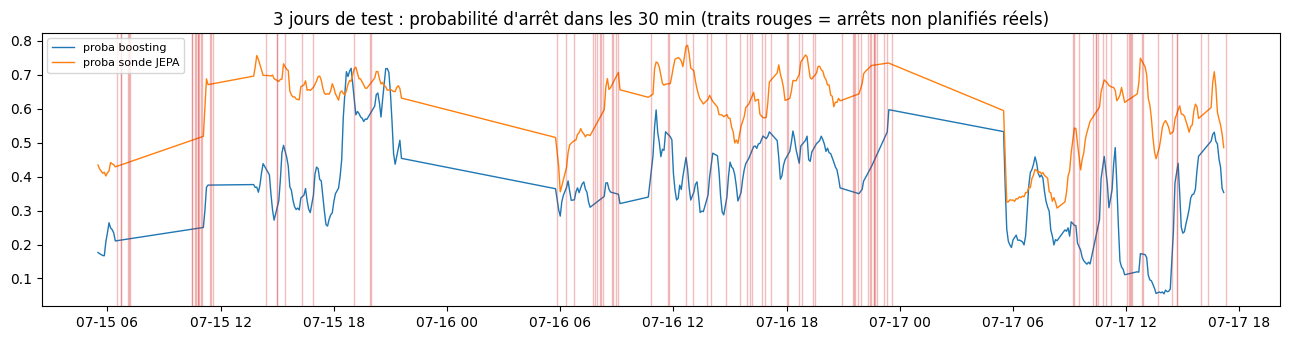

In [15]:
day = pd.Timestamp("2026-07-15")
sel = (t_end[tel] >= day) & (t_end[tel] < day + pd.Timedelta(days=3))
tt = t_end[tel][sel]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(tt, pd.Series(p_gb[sel]).rolling(3, min_periods=1).mean(), label="proba boosting", lw=1)
ax.plot(tt, pd.Series(p_probe[sel]).rolling(3, min_periods=1).mean(), label="proba sonde JEPA", lw=1)
for t in stops.debut[(stops.debut >= day) & (stops.debut < day + pd.Timedelta(days=3))]:
    ax.axvline(t, color="C3", alpha=0.3, lw=1)
ax.set_title("3 jours de test : probabilité d'arrêt dans les 30 min (traits rouges = arrêts non planifiés réels)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(RESULTS_DIR / "exemple_3_jours.png", dpi=110); plt.show()

## 7. Conclusions (exécution du 07/10/2026)

**Résultat principal.** Sur la Tablette mouleuse, prévoir un arrêt non planifié 30 minutes à l'avance est **faiblement possible**. Tous les modèles plafonnent autour d'un ROC-AUC de 0,56 à 0,58. Le JEPA fait **jeu égal avec les baselines, sans les dépasser**.

| Modèle (test mai → août 2026) | ROC-AUC | Précision top 10 % |
|---|---|---|
| Hasard | 0,50 | 0,36 |
| Nb d'arrêts dans les 4 h précédentes | 0,56 | 0,49 |
| Gradient boosting (features manuelles) | 0,57 | 0,47 |
| JEPA + sonde linéaire (2 seeds) | 0,56 | 0,48 |
| JEPA score de surprise | 0,51 | 0,34 |
| Transformer supervisé, init. JEPA | 0,56 | 0,46 |
| Transformer supervisé, init. aléatoire | 0,58 | 0,50 |

**Lecture**
- **Le signal est faible mais réel.** Quand on alerte sur les 10 % d'instants les plus risqués, environ 49 % sont suivis d'un arrêt, contre 36 % au hasard.
- **Les arrêts viennent en grappes.** La meilleure information disponible est simplement « il y a eu des arrêts récemment ». Les variables de cadence, de micro-arrêts et d'écart entre impulsions capteur n'y ajoutent presque rien.
- **Le JEPA apprend des représentations correctes** : pas d'effondrement, et la sonde linéaire atteint le niveau des baselines. Mais il n'apporte **rien de plus**, et l'initialisation JEPA ne bat pas l'initialisation aléatoire au fine-tuning. Sur ce signal, la représentation apprise sans étiquettes ne capte pas de précurseur que le supervisé ne verrait pas.
- **Toutes les zones ne se valent pas.** La zone **pré-égouttage** est la plus prévisible (AUC 0,64 ; « Pré égouttage saturé » est un phénomène qui s'installe progressivement). La zone mouleuse l'est peu (0,55), et la zone bassines pas du tout. Ça a du sens : certaines pannes ont des signes avant-coureurs dans la cadence, d'autres sont brutales (casse, capteur).

**Limites**
- Les variables disponibles ne décrivent que des **cycles et des arrêts**. Il n'y a ni vibration, ni température, ni courant moteur, alors que c'est là qu'un précurseur de panne mécanique se verrait.
- Le jeu couvre 1 an d'une seule machine. Le test (été 2026) contient nettement plus d'arrêts que le train (36 % contre 25,5 % de positifs).
- Les hyperparamètres n'ont pas été optimisés : un seul réglage a été testé, pour rester rapide sur CPU.

**Pistes**
1. **Cibler la zone pré-égouttage** (ou « Pré égouttage saturé ») plutôt que tous les arrêts : c'est la seule où le signal est net.
2. **Travailler à une granularité plus fine** : séquence brute des temps de cycle (1 token = 1 cycle) plutôt que des agrégats de 5 minutes. C'est là qu'un JEPA a le plus de chances de capter une dérive de cadence.
3. **Demander s'il existe des capteurs sur la mouleuse ou le pré-égouttage** (automate, vibration, niveau, débit). C'est la donnée qui rendrait le JEPA vraiment pertinent.
4. Valider avec la maintenance quels arrêts sont de vraies pannes, et lesquels relèvent d'aléas comme une attente de plateaux.
